In [85]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

In [86]:
img=cv2.imread("image.jpg",cv2.IMREAD_GRAYSCALE)

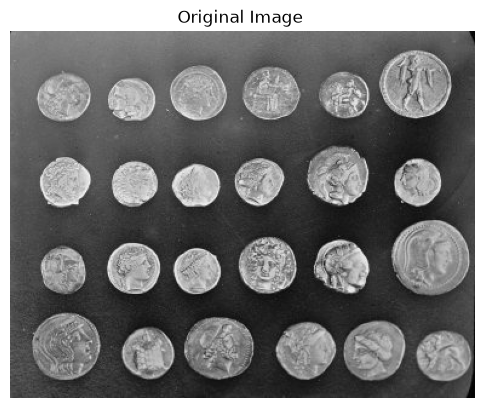

In [87]:
plt.figure(figsize=(6,5))
plt.title("Original Image ")
plt.imshow(img, cmap="gray")
plt.axis("off")
plt.show()

# Threshold segmentation 

In [88]:
fixed_threshold=127


In [89]:
# manual
global_thresh_manual=np.where(img >=fixed_threshold,255,0)
global_thresh_manual=global_thresh_manual.astype(np.uint8)

In [90]:
# built-in cv2
_,global_thresh_cv2=cv2.threshold(img,fixed_threshold,255,cv2.THRESH_BINARY)

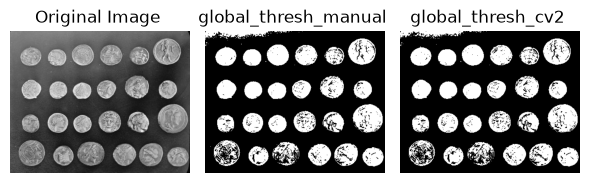

In [91]:
plt.figure(figsize=(6,5))
plt.subplot(1,3,1)
plt.title("Original Image ")
plt.imshow(img, cmap="gray")
plt.axis("off")

plt.subplot(1,3,2)
plt.title("global_thresh_manual ")
plt.imshow(global_thresh_manual, cmap="gray")
plt.axis("off")

plt.subplot(1,3,3)
plt.title("global_thresh_cv2 ")
plt.imshow(global_thresh_cv2, cmap="gray")
plt.axis("off")


plt.tight_layout()


otsu_value,otsu_thresh=cv2.threshold(img,0,255,cv2.THRESH_BINARY + cv2.THRESH_OTSU)

In [92]:
print("\nOtsu automatically selected threshold value:",otsu_value)


Otsu automatically selected threshold value: 107.0


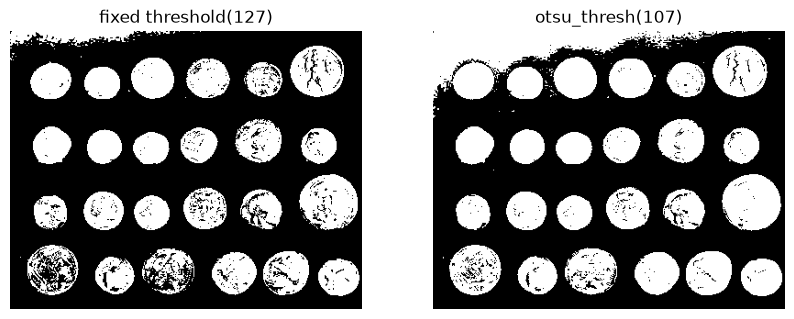

In [93]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.title("fixed threshold(127)")
plt.imshow(global_thresh_manual, cmap="gray")
plt.axis("off")

plt.subplot(1,2,2)
plt.title("otsu_thresh(107)")
plt.imshow(otsu_thresh, cmap="gray")
plt.axis("off")

plt.show()

## Show the histogram with the Otsu threshold marked for discussion 

Text(0.5, 0, 'pixel intensity')

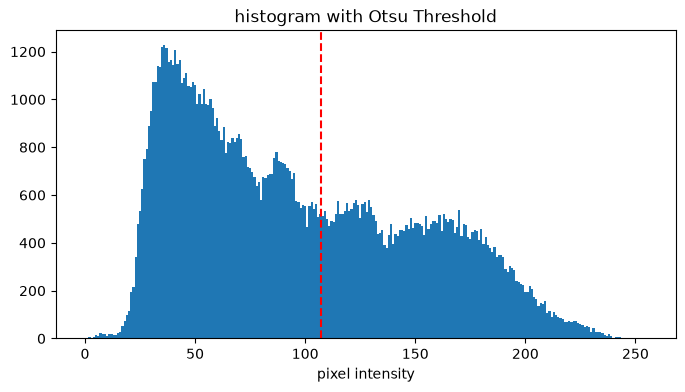

In [94]:
hist,_=np.histogram(img.flatten(),bins=256, range=(0,256))
plt.figure(figsize=(8,4))
plt.bar(range(256),hist,width=1)
plt.axvline(x=otsu_value,color="red", linestyle="--",label=f"Otsu threshold =")
plt.title("histogram with Otsu Threshold")
plt.xlabel("pixel intensity")

In [95]:
adaptive_mean=cv2.adaptiveThreshold(img,255,cv2.ADAPTIVE_THRESH_MEAN_C,cv2.THRESH_BINARY,blockSize=11,C=2)

In [96]:
adaptive_gaussian=cv2.adaptiveThreshold(img,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,cv2.THRESH_BINARY,blockSize=11,C=2)

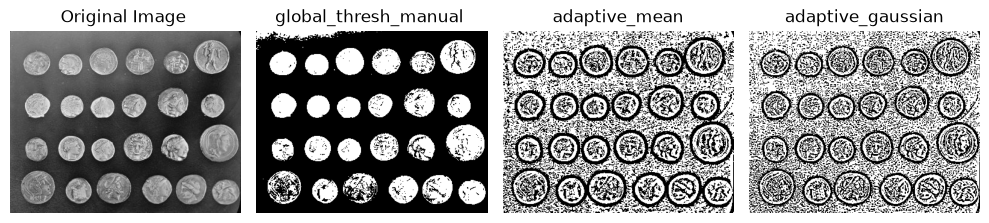

In [97]:
plt.figure(figsize=(10,5))

plt.subplot(1,4,1)
plt.title("Original Image ")
plt.imshow(img, cmap="gray")
plt.axis("off")

plt.subplot(1,4,2)
plt.title("global_thresh_manual ")
plt.imshow(global_thresh_manual, cmap="gray")
plt.axis("off")


plt.subplot(1,4,3)
plt.title("adaptive_mean")
plt.imshow(adaptive_mean, cmap="gray")
plt.axis("off")

plt.subplot(1,4,4)
plt.title("adaptive_gaussian")
plt.imshow(adaptive_gaussian, cmap="gray")
plt.axis("off")

plt.tight_layout()
plt.show()


In [98]:
extracted_region=cv2.bitwise_and(img,img,mask=otsu_thresh)

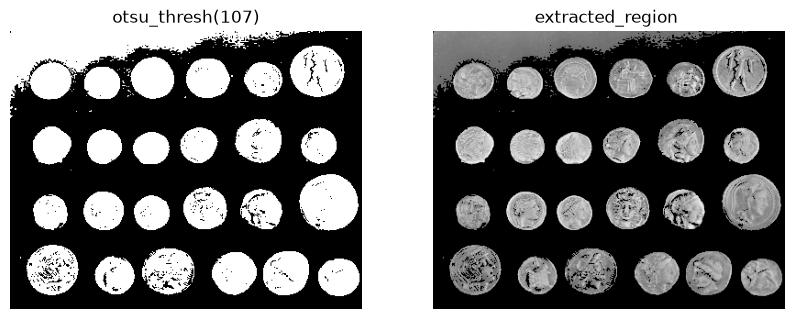

In [99]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.title("otsu_thresh(107)")
plt.imshow(otsu_thresh, cmap="gray")
plt.axis("off")


plt.subplot(1,2,2)
plt.title("extracted_region ")
plt.imshow(extracted_region, cmap="gray")
plt.axis("off")

plt.show()

In [100]:
canny_edges = cv2.Canny(img,threshold1=100, threshold2=200)

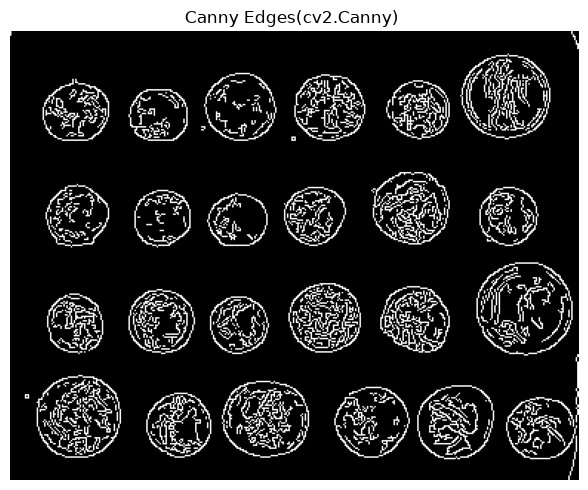

In [101]:
plt.figure(figsize=(10,5))
plt.imshow(canny_edges,cmap="gray")
plt.title("Canny Edges(cv2.Canny) ")
plt.axis("off")
plt.tight_layout()
plt.show()

## Compare Canny at different threshold settings

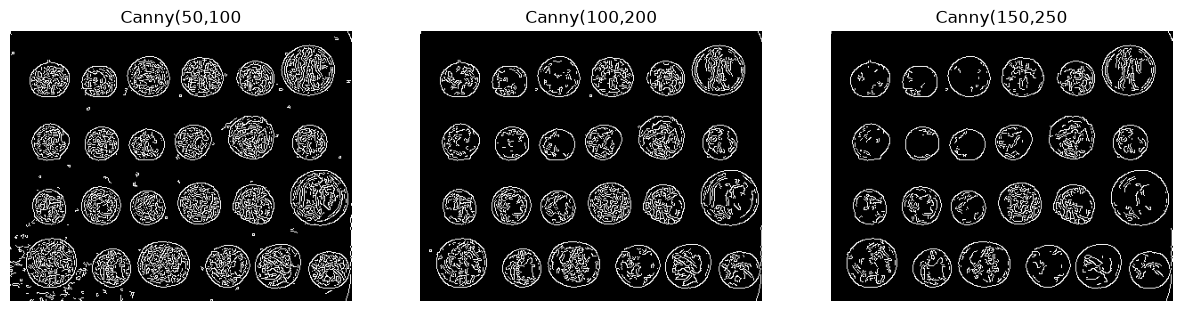

In [104]:
threshold_pairs=[(50,100),(100,200),(150,250)]
plt.figure(figsize=(15,4))
for i,(t1,t2) in enumerate(threshold_pairs):
    edges =cv2.Canny(img,t1,t2)
    plt.subplot(1,len(threshold_pairs),i+1)
    plt.imshow(edges,cmap='gray')
    plt.title(f"Canny({t1},{t2}")
    plt.axis("off")

In [116]:
_, binary=cv2.threshold(img,0,255,cv2.THRESH_BINARY + cv2.THRESH_OTSU)

In [117]:
num_labels,labels,stats,centroids =cv2.connectedComponentsWithStats(binary)

In [118]:
print("Number of  connected components found(including background):",num_labels)
print("Number of actual objects (excluding bcakground)=" ,num_labels-1)

Number of  connected components found(including background): 95
Number of actual objects (excluding bcakground)= 94


In [125]:
colored_labels=np.zeros((*labels.shape,3),dtype=np.uint8)
rng=np.random.default_rng(42)
colors=rng.integers(0,255, size=(num_labels,3))
colors[0]=[0,0,0]

In [127]:
for label_id in range (num_labels):
    colored_labels[labels == label_id]=colors[label_id]

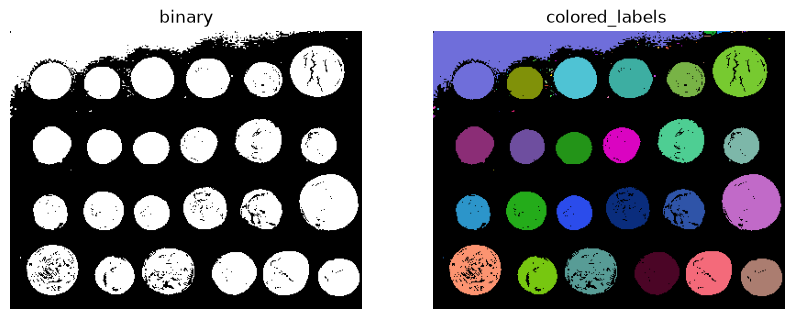

In [128]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.title("binary")
plt.imshow(binary, cmap="gray")
plt.axis("off")


plt.subplot(1,2,2)
plt.title("colored_labels ")
plt.imshow(colored_labels, cmap="gray")
plt.axis("off")

plt.show()